In [27]:
# 다항회귀로 구형하시오
# study.csv

In [28]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier  #분류
from sklearn.neighbors import KNeighborsRegressor   #예측
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler # 정규화 클래스
from sklearn.model_selection import train_test_split

In [29]:
# 데이터 읽어오기

df= pd.read_csv('data/study.csv', sep='\t')
df.head(2)

,our,score
0,0.5,10
1,1.2,8


In [30]:
# 데이터 분리, 전처리
data = df.iloc[:,:1].values
label = df.iloc[:,-1].values
data[:2]


array([[0.5],
       [1.2]])

In [31]:
# 데이터 분리
train_data, test_data, train_label, test_label = train_test_split(data, label, random_state=24)

In [32]:
# 다항회귀 형태로 변경 - 컬럼을 2개로 증가시킴.
# 제공되는 라이브러리 사용
train_poly=np.column_stack((train_data**2, train_data))
test_poly=np.column_stack((test_data**2,test_data))

In [33]:
# 모델학습
lr=LinearRegression()
lr.fit(train_poly, train_label)

# 예측
predict = lr.predict(test_poly)
print('예상 성적:',predict)

예상 성적: [63.66647333 40.80375533 86.30784498 33.28201372 52.38248424]


In [34]:
# 정확도
score=lr.score(train_poly, train_label)
score2=lr.score(test_poly, test_label)

print('tarin데이터 정확도:',score)
print('test데이터 정확도:',score2)


tarin데이터 정확도: 0.9523821481575323
test데이터 정확도: 0.9673240188829204


In [38]:
in_data = input('공부시간을 입력하세요.>> ')
in_data = float(in_data)
result = lr.predict([[in_data**2,in_data]])
print(f"공부시간에 따른 예측점수 : {result[0]:.2f} 점")

공부시간에 따른 예측점수 : 41.87 점


In [39]:
# 구간별 직선을 그리기 위해 범위 정수배열 생성
point = np.arange(1,10)

In [ ]:
# lr.coef_ : 다항회귀는 기울기가 2개 나옴, lr.intercept_ : y절편
print('기울기:', lr.coef_)
print('y 절편:',lr.intercept_)

기울기: [-0.12179331 11.61007769]
y 절편: -2.6230713406566295


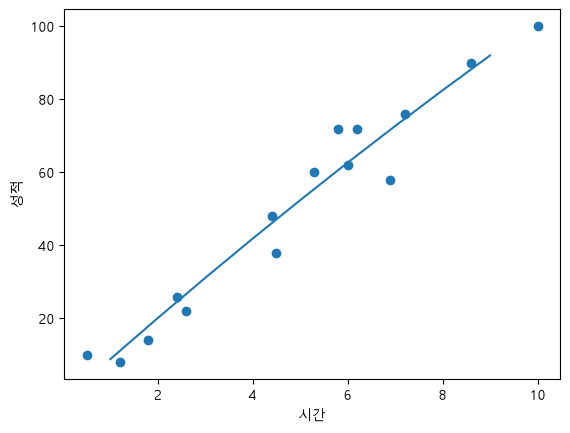

In [41]:
# 그래프
plt.scatter(train_data, train_label)
plt.plot(point, lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)

plt.xlabel('시간')
plt.ylabel('성적')
plt.show()